# 01 — EDA

Hypotheses → decisions:
- **H1** IO labels merge adjacent locations → BIO from `loc_markers`
- **H2** span vs token boundaries → tokenizer
- **H3** class imbalance → resampling / threshold
- **H4** test posts longer than train sentences → chunking
- **H5** OOV and noise in test → char features, cleaning
- **H6** Russian in test → `ru_geo_dataset`
- **H7** labeling rules train vs test → boundary rules
- **H8** test answers in train lexicon → how much to generalize

`labeling_sample` is the test domain.

### Imports

In [1]:
import ast
import json
import re
import string
from typing import List

import matplotlib.pyplot as plt
import pandas as pd

DATA = '../data'

### Competition metric (Kaggle, unchanged)

In [2]:
def hard_processing(text):
    text = re.sub(r"[{re.escape(string.punctuation)}]", "", text)
    text = re.sub(r'\d', '', text)
    text = re.sub(r'\b\w\b\s?', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text.lower()


def comp_metric(y_true: List[List[str]], y_pred: List[List[str]]):
    assert len(y_true) == len(y_pred)
    tp, fp, fn, p, = 0.0, 0.0, 0.0, 0.0
    for y_true_sample, y_pred_sample in zip(y_true, y_pred):
        y_true_sample = set([hard_processing(s) for s in y_true_sample])
        y_pred_sample = set([hard_processing(s) for s in y_pred_sample])
        tp += len(y_true_sample & y_pred_sample)
        fp += len(y_pred_sample - y_true_sample)
        fn += len(y_true_sample - y_pred_sample)
        p += len(y_true_sample)
    if tp + fp == 0:
        precision = 1.0 if p == 0 else 0.0
    else:
        precision = tp / (tp + fp)
    if tp + fn == 0:
        recall = 1.0 if p == 0 else 0.0
    else:
        recall = tp / (tp + fn)
    if precision + recall == 0:
        f1 = 0
    else:
        f1 = 2 * precision * recall / (precision + recall)
    return round(f1, 8)

### Data

In [3]:
uk = pd.read_csv(f'{DATA}/uk_geo_dataset.csv')
sample = pd.read_csv(f'{DATA}/labeling_sample.csv')
test = pd.read_csv(f'{DATA}/test.csv')

uk['spans'] = uk['loc_markers'].map(ast.literal_eval)
sample['spans'] = sample['loc_markers'].map(ast.literal_eval)
sample['locations'] = sample['locations'].map(ast.literal_eval)

train = uk.sample(100_000, random_state=42)

print('uk:', uk.shape, '| labeling_sample:', sample.shape, '| test:', test.shape)

uk: (1010000, 6) | labeling_sample: (26, 4) | test: (477, 3)


### Tokenizer

In [4]:
TOKEN_RE = re.compile(r"\w+(?:['’ʼ]\w+)*|[^\w\s]")


def tokenize(text):
    return [(m.group(), m.start(), m.end()) for m in TOKEN_RE.finditer(text)]


def words(text):
    return [w.lower() for w in TOKEN_RE.findall(text) if w[0].isalnum()]


for df in [train, sample, test]:
    df['n_tokens'] = df['text'].map(lambda t: len(tokenize(t)))

tokenize("Вибухи в Києві, «Ірпені» та на вул.Солом'янській!")

[('Вибухи', 0, 6),
 ('в', 7, 8),
 ('Києві', 9, 14),
 (',', 14, 15),
 ('«', 16, 17),
 ('Ірпені', 17, 23),
 ('»', 23, 24),
 ('та', 25, 27),
 ('на', 28, 30),
 ('вул', 31, 34),
 ('.', 34, 35),
 ("Солом'янській", 35, 48),
 ('!', 48, 49)]

## H1. IO vs BIO

In [5]:
pq_labels = pd.read_parquet(f'{DATA}/uk_geo_dataset_processed_v1.parquet', columns=['labels'])
print('Parquet labels:', {label for row in pq_labels['labels'].head(10_000) for label in json.loads(row)})

Parquet labels: {'O', 'LOC'}


In [6]:
def merge_adjacent(text, spans):
    merged = []
    for s, e in sorted(spans):
        if merged and text[merged[-1][1]:s].strip() == '':
            merged[-1][1] = e
        else:
            merged.append([s, e])
    return [text[s:e] for s, e in merged]


gold = [[t[s:e] for s, e in spans] for t, spans in zip(train['text'], train['spans'])]
io = [merge_adjacent(t, spans) for t, spans in zip(train['text'], train['spans'])]

changed = [i for i, (g, m) in enumerate(zip(gold, io)) if len(g) != len(m)]
print(f'Sentences merged by IO: {len(changed) / len(train):.2%}')
print('Oracle F1 with IO labels:', comp_metric(gold, io))

Sentences merged by IO: 0.61%


Oracle F1 with IO labels: 0.97085148


In [7]:
for i in changed[:5]:
    print(gold[i], '->', io[i])

['Туровці(Турівці', 'Прилуцького повіту', 'Полтавської губерні(теперішня', 'Чернігівської області'] -> ['Туровці(Турівці', 'Прилуцького повіту Полтавської губерні(теперішня', 'Чернігівської області']
['Скобелево', 'Казанківського району'] -> ['Скобелево Казанківського району']
['Бжезьник', 'Болеславець', 'Нижньосілезького воєводства'] -> ['Бжезьник', 'Болеславець Нижньосілезького воєводства']
['Роздільнянському районі', 'селищі', 'Лиманському'] -> ['Роздільнянському районі', 'селищі Лиманському']
['Івано', '-Франківської області'] -> ['Івано-Франківської області']


## H2. Span vs token boundaries

In [8]:
def span_matches_tokens(text, s, e):
    tokens = tokenize(text)
    starts = {start for _, start, _ in tokens}
    ends = {end for _, _, end in tokens}
    return s in starts and e in ends


for name, df in [('train', train), ('labeling_sample', sample)]:
    checks = [span_matches_tokens(t, s, e) for t, spans in zip(df['text'], df['spans']) for s, e in spans]
    print(f'{name}: aligned spans {sum(checks) / len(checks):.2%}')

train: aligned spans 99.43%
labeling_sample: aligned spans 96.88%


In [9]:
bad = [(t[s:e], t[max(s - 10, 0):e + 10])
       for t, spans in zip(train['text'], train['spans']) for s, e in spans
       if not span_matches_tokens(t, s, e)]
pd.DataFrame(bad[:10], columns=['span', 'context'])

,span,context
0,Новому Уренгої (Рос,заклад в Новому Уренгої (Росія) запроп
1,Рогатинщині відно,На Рогатинщині відновив роботу
2,"Н-10 «Стрий-Мамалига»,пр","ої дороги Н-10 «Стрий-Мамалига»,прес-служба"
3,Житомир-Киї,Бев/НПУ” (Житомир-Київ).
4,Харкова Геннаді,єння меру Харкова Геннадію Кернесу
5,"Литви, суд","ські сили Литви, судна НАТО і"
6,"Майдан - Копищанський», «Дол","ревини», «Майдан - Копищанський», «Дольськ», «Са"
7,Росії на прое,США щодо Росії на проект газопро
8,Мелешківської захоті,елян Луки-Мелешківської захотіли вивести
9,Донецькій області внаслідок вибуху гра,У Донецькій області внаслідок вибуху гранати н...


## H3. Class imbalance

In [10]:
for name, df in [('train', train), ('labeling_sample', sample)]:
    has_loc = (df['spans'].map(len) > 0).mean()
    loc_tokens = sum(len(tokenize(t[s:e])) for t, spans in zip(df['text'], df['spans']) for s, e in spans)
    print(f'{name}: texts with LOC = {has_loc:.1%}, LOC tokens = {loc_tokens / df["n_tokens"].sum():.2%}')

train: texts with LOC = 23.1%, LOC tokens = 2.38%
labeling_sample: texts with LOC = 61.5%, LOC tokens = 3.32%


## H4. Text length

In [11]:
pd.DataFrame({
    'train': train['n_tokens'].describe(percentiles=[.5, .9, .99]),
    'labeling_sample': sample['n_tokens'].describe(percentiles=[.5, .9, .99]),
    'test': test['n_tokens'].describe(percentiles=[.5, .9, .99]),
}).round()

,train,labeling_sample,test
count,100000.0,26.0,477.0
mean,18.0,54.0,69.0
std,8.0,54.0,73.0
min,5.0,2.0,1.0
50%,16.0,36.0,46.0
90%,29.0,144.0,148.0
99%,41.0,184.0,361.0
max,70.0,187.0,599.0


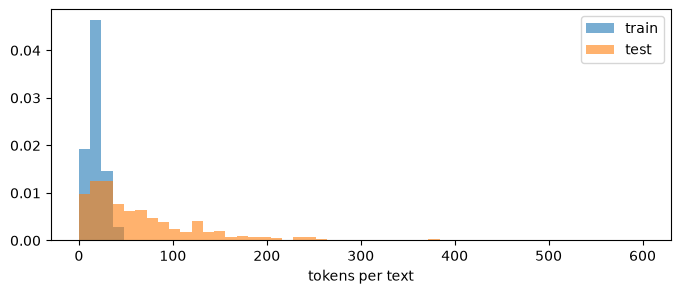

In [12]:
plt.figure(figsize=(8, 3))
plt.hist(train['n_tokens'], bins=50, range=(0, 600), density=True, alpha=.6, label='train')
plt.hist(test['n_tokens'], bins=50, range=(0, 600), density=True, alpha=.6, label='test')
plt.xlabel('tokens per text')
plt.legend()
plt.show()

## H5. OOV and noise

In [13]:
vocab = {w for text in uk['text'] for w in words(text)}


def oov_rate(texts):
    all_words = [w for text in texts for w in words(text)]
    return sum(w not in vocab for w in all_words) / len(all_words)


gold_locations = [loc for locs in sample['locations'] for loc in locs]

print('Train vocabulary:', len(vocab))
print(f'OOV test:             {oov_rate(test["text"]):.1%}')
print(f'OOV labeling_sample:  {oov_rate(sample["text"]):.1%}')
print(f'OOV sample locations: {oov_rate(gold_locations):.1%}')

Train vocabulary: 432186
OOV test:             5.1%
OOV labeling_sample:  4.3%
OOV sample locations: 7.0%


In [14]:
NOISE = {
    'emoji': r'[\U0001F300-\U0001FAFF\u2600-\u27BF]',
    'latin': r'[A-Za-z]{3,}',
    'URL': r'https?://|t\.me/',
    '@mention': r'@\w+',
    '#hashtag': r'#\w+',
}
for kind, pattern in NOISE.items():
    print(f'{kind:10} train {train["text"].str.contains(pattern).mean():4.0%} | '
          f'sample {sample["text"].str.contains(pattern).mean():4.0%} | '
          f'test {test["text"].str.contains(pattern).mean():4.0%}')

emoji      train   0% | sample  69% | test  60%
latin      train   6% | sample  19% | test  30%
URL        train   0% | sample   0% | test   4%
@mention   train   0% | sample   8% | test   4%


#hashtag   train   0% | sample   4% | test   4%


## H6. Test language

In [15]:
def detect_lang(text):
    has_ru = re.search('[ыэъё]', text.lower()) is not None
    has_uk = re.search('[іїєґ]', text.lower()) is not None
    if has_ru and has_uk:
        return 'mixed'
    if has_ru:
        return 'ru'
    if has_uk:
        return 'uk'
    return 'unknown'


test['text'].map(detect_lang).value_counts(normalize=True).round(2)

text
uk         0.90
ru         0.07
unknown    0.03
mixed      0.00
Name: proportion, dtype: float64

## H7. Keywords in spans

In [16]:
KEYWORDS = ['вул', 'просп', 'бульв', 'площ', 'район', 'област', 'міст', 'сел', 'метро', 'тц']


def keyword_stats(df):
    rows = []
    for text, spans in zip(df['text'], df['spans']):
        for s, e in spans:
            inside = words(text[s:e])
            outside = words(text[:s])[-1:] + words(text[e:])[:1]
            for kw in KEYWORDS:
                if any(w.startswith(kw) for w in inside):
                    rows.append((kw, 'inside'))
                if any(w.startswith(kw) for w in outside):
                    rows.append((kw, 'adjacent'))
    return pd.DataFrame(rows, columns=['keyword', 'where']).value_counts().unstack(fill_value=0)


keyword_stats(train)

where,adjacent,inside
keyword,,
сел,403,10
област,63,1046
район,262,432
міст,530,25
вул,86,366
просп,3,53
бульв,7,15
площ,11,87
метро,21,14


In [17]:
keyword_stats(sample)

where,inside,adjacent
keyword,,
просп,2,0
тц,1,0
район,1,2
вул,3,0


In [18]:
print(gold_locations)

['Проспект Бандери', 'Київщині', 'Чорнобиль', 'Київ', 'Тетерів', 'Фастів', 'Біла Церква', 'Миронівка', 'Бориспіль', 'Яготин', 'Баришівка', 'проспекті Івасюка', 'Києва', 'Хелма', 'Києву', 'ТЦ Аркадія', 'Фастовском', 'Бучанском', 'Троєщині', 'Шевченківському районі', 'Героїв Дніпра', "вул. Солом'янська, 28", 'Києвом', 'Васильковом', 'Києва', 'Броварах', 'Київщині', 'Києві', 'Подолі', 'Пскові', 'вулиці Здолбунівській', 'вул. Здолбунівська, 1']


In [19]:
streets = train[train['text'].str.contains(r'\bвул(?:\.|иц)') & (train['spans'].map(len) > 0)]
for text, spans in zip(streets['text'].head(8), streets['spans'].head(8)):
    print([text[s:e] for s, e in spans], '<-', text[:130])

['вулицю Ірини Вільде'] <- "Опель" повертав наліво (на вулицю Ірини Вільде) і зачепив "Тойоту".
['вул. Грушевського'] <- Нагадаємо, першу модульну вбиральню встановили на вул. Грушевського.
['вулиці Конякіна'] <- "Сьогодні (8 січня - прим.ред.) по обіді на вулиці Конякіна із вікна будинку випало двоє 15-річних дівчат.
['вулиці Різницькій', 'Києві'] <- Прокуратура Києва порушила кримінальну справу за фактом загибелі будівельника на будівництві у дворі будівлі Генеральної прокурату
['вулиці Спартака'] <- Тільки на центральній вулиці Спартака їх встановлено кілька.
['вул. Об’їзній.'] <- Нелегальний газозаправний пункт діяв на вул. Об’їзній.
['Парижа', 'вул. абата Грегуара, 43', 'Люксембурзького саду'] <- Приїхавши до Парижа, Шульц зупинився у "Східному готелі" (Hotel d'Orient) на вул. абата Грегуара, 43, неподалік від Люксембурзьког
['Одесі', 'вулиці Єврейська'] <- В Одесі на вулиці Єврейська в регіональному главку Національної поліції над сходами, травмувавши правоохоронців.


## H8. Train lexicon coverage

In [20]:
train_lexicon = {hard_processing(t[s:e]) for t, spans in zip(uk['text'], uk['spans']) for s, e in spans}
found = [loc for loc in gold_locations if hard_processing(loc) in train_lexicon]
missing = [loc for loc in gold_locations if hard_processing(loc) not in train_lexicon]

print('Unique train locations:', len(train_lexicon))
print(f'Sample answers in train lexicon: {len(found)}/{len(gold_locations)}')
print('Missing:', missing)

Unique train locations: 43540
Sample answers in train lexicon: 25/32
Missing: ['Проспект Бандери', 'проспекті Івасюка', 'ТЦ Аркадія', 'Фастовском', 'Бучанском', 'вулиці Здолбунівській', 'вул. Здолбунівська, 1']


## Summary

`labeling_sample` has 32 locations; conclusions are indicative.

| # | Result | Decision |
|---|---|---|
| H1 ✅ | IO merges locations in 0.6% of sentences; F1 ceiling 0.971 | BIO from `loc_markers` |
| H2 ✅ | 99.4% of spans align; the rest are broken labels | Own tokenizer (hyphen split), drop broken spans |
| H3 ✅ | LOC tokens: 2.4% train, 3.3% sample | No resampling; threshold on validation |
| H4 ✅ | Train ≤ 70 tokens, test up to 599 (median 46) | Chunk posts by line |
| H5 ❌ | OOV 5%, emoji in 60% of posts | Emoji → `<unk>`, no heavy cleaning |
| H6 ❌ | 7% Russian | `ru_geo_dataset` optional |
| H7 ❌ | Street type, «області», house number inside spans in both | No boundary rules; keep house numbers |
| H8 ~ | 25/32 answers in train lexicon; streets and malls missing | Context + char features |